# Week 2: Exploratory Data Analysis (EDA)

## Project Overview

This notebook explores the cleaned Food Delivery dataset
prepared during Week 1.

The objective is to understand delivery duration patterns,
compare operational factors, analyze delivery distance,
and identify evidence-based business observations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

project_root = Path.cwd().parent

data_path = (
    project_root / "data" / "processed" / "food_delivery_cleaned.csv"
)

print("Project directory:", project_root)
print("Dataset exists:", data_path.exists())

Project directory: c:\Users\salih\Documents\food-delivery-data-analysis
Dataset exists: True


In [2]:
df = pd.read_csv(data_path, parse_dates=["Order_Date"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (45584, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.00,4.20,30.33,78.05,30.40,78.12,2022-02-12,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.00,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.00,4.70,10.00,76.31,10.04,76.35,2022-02-13,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.00,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.00,4.70,18.56,73.92,18.65,74.01,2022-03-04,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.00,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.00,4.30,30.90,75.81,30.92,75.83,2022-02-13,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.00,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.00,4.70,26.46,80.37,26.59,80.50,2022-02-14,19:50,20:05,Fog,Jam,1,Snack,scooter,1.00,No,Metropolitian,41


## 1. Delivery Duration Baseline

### Objective

The objective of this section is to establish a baseline
understanding of delivery duration.

We will calculate the key descriptive statistics, including
count, mean, median, minimum, maximum, quartiles, and
standard deviation.

The analysis will help us understand the typical delivery time
and the overall variation in delivery duration.

### Target Column

The target variable for this analysis is `Time_taken (min)`,
which represents the time taken to complete each delivery.

In [3]:
# Identify the delivery duration column
duration_col = "Time_taken (min)"

# Convert duration values to numeric
duration = pd.to_numeric(df[duration_col], errors="coerce")

# Keep valid duration records
valid_duration = duration.dropna()

# Calculate baseline statistics
baseline_stats = pd.DataFrame({
    "Metric": [
        "Count",
        "Mean",
        "Median",
        "Minimum",
        "Maximum",
        "25th Percentile",
        "75th Percentile",
        "Standard Deviation"
    ],
    "Value": [
        valid_duration.count(),
        valid_duration.mean(),
        valid_duration.median(),
        valid_duration.min(),
        valid_duration.max(),
        valid_duration.quantile(0.25),
        valid_duration.quantile(0.75),
        valid_duration.std()
    ]
})

print("Total records:", len(df))
print("Valid duration records:", valid_duration.count())
print("Missing or invalid duration records:", duration.isna().sum())

display(baseline_stats)

Total records: 45584
Valid duration records: 45584
Missing or invalid duration records: 0


,Metric,Value
0,Count,45584.00
1,Mean,26.29
2,Median,26.00
3,Minimum,10.00
4,Maximum,54.00
5,25th Percentile,19.00
6,75th Percentile,32.00
7,Standard Deviation,9.38


### Baseline Results

The dataset contains 45,584 valid delivery records, with no
missing or invalid values in the delivery duration column.

The average delivery duration is 26.29 minutes, while the
median is 26 minutes.

The first and third quartiles are 19 and 32 minutes,
respectively, indicating that the middle 50% of deliveries
fall within this interval.

The minimum delivery duration is 10 minutes, and the maximum
is 54 minutes, with a standard deviation of 9.38 minutes.

Further analysis is required to assess the distribution's
skewness and identify potential extreme values.

## 2. Distribution Shape and Outlier Detection

### Objective

This section examines the distribution of delivery duration
using the skewness coefficient.

It also identifies potential outliers using the
Interquartile Range (IQR) method.

The purpose is to understand the spread of delivery times
and determine whether unusually short or long deliveries
exist in the dataset.

In [4]:
# Calculate skewness
skewness = valid_duration.skew()

# Calculate IQR
Q1 = valid_duration.quantile(0.25)
Q3 = valid_duration.quantile(0.75)
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Identify potential outliers
outliers = valid_duration[
    (valid_duration < lower_bound) |
    (valid_duration > upper_bound)
]

# Display results
distribution_results = pd.DataFrame({
    "Metric": [
        "Skewness",
        "Q1",
        "Q3",
        "IQR",
        "Lower Bound",
        "Upper Bound",
        "Outlier Count",
        "Outlier Percentage"
    ],
    "Value": [
        skewness,
        Q1,
        Q3,
        IQR,
        lower_bound,
        upper_bound,
        len(outliers),
        (len(outliers) / len(valid_duration)) * 100
    ]
})

display(distribution_results)

,Metric,Value
0,Skewness,0.49
1,Q1,19.00
2,Q3,32.00
3,IQR,13.00
4,Lower Bound,-0.50
5,Upper Bound,51.50
6,Outlier Count,270.00
7,Outlier Percentage,0.59


### Distribution and Outlier Findings

The delivery duration distribution has a positive skewness
of 0.49, indicating a slight right-skewed distribution.

The Interquartile Range (IQR) is 13 minutes, with an upper
outlier boundary of 51.5 minutes and a lower boundary of
-0.5 minutes.

Using the IQR method, 270 potential outliers were identified,
representing approximately 0.59% of all valid delivery records.

No lower-end outliers were detected.

These records will be retained because statistical outliers
are not necessarily data errors. Further investigation may
be required before considering their removal.

## 3. Delivery Duration by Operational Factors

### Objective

This section compares delivery duration across three
operational factors:

1. Road traffic density.
2. Weather conditions.
3. Vehicle type.

For each category, we calculate the number of deliveries,
mean delivery duration, and median delivery duration.

The comparison helps identify differences in delivery
duration across operational groups.

In [5]:
# Define the operational factors
operational_factors = [
    "Road_traffic_density",
    "Weather_conditions",
    "Type_of_vehicle"
]

# Calculate delivery statistics for each factor
for factor in operational_factors:

    print(f"\nDelivery Duration by {factor}")

    factor_analysis = (
        df.groupby(factor, dropna=False)[duration_col]
        .agg(
            Delivery_Count="count",
            Mean_Duration="mean",
            Median_Duration="median"
        )
        .sort_values("Mean_Duration", ascending=False)
        .reset_index()
    )

    display(factor_analysis)


Delivery Duration by Road_traffic_density


,Road_traffic_density,Delivery_Count,Mean_Duration,Median_Duration
0,Jam,14139,31.18,31.00
1,High,4423,27.24,27.00
2,Medium,10945,26.70,27.00
3,Low,16077,21.46,21.00



Delivery Duration by Weather_conditions


,Weather_conditions,Delivery_Count,Mean_Duration,Median_Duration
0,Cloudy,7533,28.92,28.00
1,Fog,8269,28.74,28.00
2,Windy,7422,26.12,26.00
3,Sandstorms,7494,25.88,26.00
4,Stormy,7584,25.87,26.00
5,Sunny,7282,21.86,20.00



Delivery Duration by Type_of_vehicle


,Type_of_vehicle,Delivery_Count,Mean_Duration,Median_Duration
0,motorcycle,26429,27.61,26.00
1,bicycle,68,26.43,26.00
2,scooter,15273,24.48,24.00
3,electric_scooter,3814,24.47,24.00


### Vehicle Type Analysis

The motorcycle category recorded the highest mean delivery
duration at 27.61 minutes, with a median of 26 minutes.

Scooters and electric scooters recorded similar mean
delivery durations of 24.48 and 24.47 minutes, respectively.
Both categories had a median of 24 minutes.

The bicycle category recorded a mean duration of 26.43
minutes. However, it contains only 68 records, which is
substantially smaller than the other vehicle categories.

These results show differences in observed delivery
durations across vehicle categories, but they do not
establish that vehicle type causes delivery delays.
### Road Traffic Density Analysis

The Jam category recorded the highest mean delivery duration
at 31.18 minutes, while the Low traffic category recorded
the lowest mean at 21.46 minutes.

The difference between these two categories was 9.72 minutes.

High and Medium traffic categories recorded mean durations
of 27.24 and 26.70 minutes, respectively.

### Weather Conditions Analysis

Cloudy weather recorded the highest mean delivery duration
at 28.92 minutes, followed closely by Fog at 28.74 minutes.

Sunny weather recorded the lowest mean duration at
21.86 minutes.

The difference between Cloudy and Sunny conditions was
7.06 minutes.

### Interpretation and Limitations

The results show observed differences in delivery duration
across traffic and weather categories.

These comparisons are descriptive and do not establish
causation.

Some missing traffic and weather values were imputed during
Week 1 using the mode. Therefore, the corresponding group
statistics may include imputed observations.

## 4. Delivery Distance Analysis

### Objective

This section examines the geographical distance between
restaurants and delivery locations.

Since the dataset does not contain a direct distance column,
distance will be calculated using the Haversine formula
based on latitude and longitude coordinates.

The calculated distance represents straight-line
geographical distance, not actual road distance.

Before calculating distance, the coordinate fields will
be checked for missing, zero, and invalid values.

In [6]:
# Define coordinate columns
coordinate_cols = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

# Convert coordinates to numeric
coordinates = df[coordinate_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

# Check missing values
print("Missing coordinates:")
display(coordinates.isna().sum().to_frame("Missing_Count"))

# Check coordinate ranges
print("Coordinate summary:")
display(coordinates.describe())

# Count records containing zero coordinates
zero_coordinate_rows = (coordinates == 0).any(axis=1).sum()

# Count records with invalid geographic ranges
invalid_latitude = (
    (coordinates["Restaurant_latitude"].abs() > 90) |
    (coordinates["Delivery_location_latitude"].abs() > 90)
)

invalid_longitude = (
    (coordinates["Restaurant_longitude"].abs() > 180) |
    (coordinates["Delivery_location_longitude"].abs() > 180)
)

invalid_coordinate_rows = (
    invalid_latitude | invalid_longitude
).sum()

print("Rows containing at least one zero coordinate:", zero_coordinate_rows)
print("Rows with invalid geographic ranges:", invalid_coordinate_rows)

Missing coordinates:


,Missing_Count
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0


Coordinate summary:


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
count,45584.00,45584.00,45584.00,45584.00
mean,17.02,70.23,17.47,70.84
std,8.19,22.89,7.34,21.12
min,-30.91,-88.37,0.01,0.01
25%,12.93,73.17,12.99,73.28
50%,18.55,75.90,18.63,76.00
75%,22.73,78.04,22.79,78.11
max,30.91,88.43,31.05,88.56


Rows containing at least one zero coordinate: 3640
Rows with invalid geographic ranges: 0


### Coordinate Quality Assessment

No missing coordinate values were found, and all coordinates
fall within the general valid geographic ranges.

However, 3,640 records contain at least one zero coordinate.

Zero coordinates may represent placeholder or incomplete
location data. These records require further inspection
before calculating delivery distances.

In [7]:
# Count zero values in each coordinate column
zero_counts = (coordinates == 0).sum()

print("Zero values by coordinate column:")
display(zero_counts.to_frame("Zero_Count"))

# Check restaurant coordinates
restaurant_zero = (
    (coordinates["Restaurant_latitude"] == 0) |
    (coordinates["Restaurant_longitude"] == 0)
)

# Check delivery location coordinates
delivery_zero = (
    (coordinates["Delivery_location_latitude"] == 0) |
    (coordinates["Delivery_location_longitude"] == 0)
)

print("Records with zero restaurant coordinates:", restaurant_zero.sum())
print("Records with zero delivery coordinates:", delivery_zero.sum())

# Check negative coordinate values
negative_counts = (coordinates < 0).sum()

print("Negative coordinate values:")
display(negative_counts.to_frame("Negative_Count"))

# Inspect sample records containing zero coordinates
print("Sample records with zero coordinates:")

display(
    df.loc[
        (coordinates == 0).any(axis=1),
        ["ID"] + coordinate_cols + [duration_col]
    ].head(10)
)

Zero values by coordinate column:


,Zero_Count
Restaurant_latitude,3640
Restaurant_longitude,3640
Delivery_location_latitude,0
Delivery_location_longitude,0


Records with zero restaurant coordinates: 3640
Records with zero delivery coordinates: 0
Negative coordinate values:


,Negative_Count
Restaurant_latitude,431
Restaurant_longitude,162
Delivery_location_latitude,0
Delivery_location_longitude,0


Sample records with zero coordinates:


,ID,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_taken (min)
24,0x2876,0.00,0.00,0.11,0.11,35
43,0xc1ff,0.00,0.00,0.03,0.03,15
48,0x8e6c,0.00,0.00,0.08,0.08,49
50,0x395b,0.00,0.00,0.06,0.06,30
58,0x98aa,0.00,0.00,0.02,0.02,15
59,0x273a,0.00,0.00,0.04,0.04,16
63,0x5ded,0.00,0.00,0.08,0.08,15
64,0x1a70,0.00,0.00,0.02,0.02,17
67,0xc606,0.00,0.00,0.05,0.05,27
72,0xc444,0.00,0.00,0.11,0.11,25


### Investigation of Negative Restaurant Coordinates

The coordinate inspection identified negative values in
restaurant latitude and longitude.

Although negative coordinates can be geographically valid,
their consistency with the delivery locations needs to be
examined before calculating delivery distances.

No records will be deleted from the original dataset.

In [8]:
# Identify records with negative restaurant coordinates
negative_restaurant = (
    (coordinates["Restaurant_latitude"] < 0) |
    (coordinates["Restaurant_longitude"] < 0)
)

# Count records with negative coordinates
print(
    "Records with negative restaurant coordinates:",
    negative_restaurant.sum()
)

# Check overlap between negative latitude and longitude
negative_lat = coordinates["Restaurant_latitude"] < 0
negative_lon = coordinates["Restaurant_longitude"] < 0

print("Negative latitude only:", (negative_lat & ~negative_lon).sum())
print("Negative longitude only:", (~negative_lat & negative_lon).sum())
print("Both latitude and longitude negative:", (negative_lat & negative_lon).sum())

# Inspect sample records
negative_samples = df.loc[
    negative_restaurant,
    [
        "ID",
        "City",
        "Restaurant_latitude",
        "Restaurant_longitude",
        "Delivery_location_latitude",
        "Delivery_location_longitude",
        duration_col
    ]
]

display(negative_samples.head(15))

# Count negative-coordinate records by city
display(
    negative_samples["City"]
    .value_counts(dropna=False)
    .to_frame("Record_Count")
)

Records with negative restaurant coordinates: 431
Negative latitude only: 269
Negative longitude only: 0
Both latitude and longitude negative: 162


,ID,City,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_taken (min)
83,0xc042,Metropolitian,-27.16,78.06,27.23,78.13,15
274,0xc044,Metropolitian,-27.17,78.02,27.23,78.08,31
280,0x4db,Urban,-18.55,-73.80,18.61,73.86,12
416,0xc003,Metropolitian,-30.37,-78.07,30.50,78.20,20
525,0x473,Metropolitian,-12.33,-76.63,12.39,76.69,16
574,0x5af,Urban,-12.32,76.60,12.33,76.61,29
753,0x462,Metropolitian,-23.36,-85.33,23.45,85.42,15
1050,0xc013,Urban,-26.48,-80.35,26.49,80.36,15
1082,0xc086,Metropolitian,-15.55,73.76,15.61,73.82,29
1148,0x566,Metropolitian,-12.34,76.62,12.39,76.67,33


,Record_Count
City,
Metropolitian,325
Urban,104
Semi-Urban,2


### Negative Coordinate Investigation

A total of 431 records contain negative restaurant coordinates.

Among these records, 269 have negative latitude only, while
162 have both negative latitude and longitude.

No records have negative longitude only.

The negative restaurant coordinates appear inconsistent
with the corresponding positive delivery coordinates in
the inspected sample.

These coordinates will not be corrected by changing their
signs. Records with zero or negative restaurant coordinates
will be excluded from distance calculations only, while
the original dataset remains unchanged.

In [9]:
# Identify zero and negative restaurant coordinates
zero_restaurant = (
    (coordinates["Restaurant_latitude"] == 0) |
    (coordinates["Restaurant_longitude"] == 0)
)

negative_restaurant = (
    (coordinates["Restaurant_latitude"] < 0) |
    (coordinates["Restaurant_longitude"] < 0)
)

# Check overlap between the two conditions
overlap_count = (
    zero_restaurant & negative_restaurant
).sum()

# Identify records with suspicious restaurant coordinates
invalid_restaurant = zero_restaurant | negative_restaurant

# Keep records with positive restaurant coordinates
valid_distance_mask = ~invalid_restaurant

print("Records with zero restaurant coordinates:", zero_restaurant.sum())
print("Records with negative restaurant coordinates:", negative_restaurant.sum())
print("Overlap between zero and negative records:", overlap_count)
print("Records excluded from distance analysis:", invalid_restaurant.sum())
print("Records available for distance analysis:", valid_distance_mask.sum())

Records with zero restaurant coordinates: 3640
Records with negative restaurant coordinates: 431
Overlap between zero and negative records: 0
Records excluded from distance analysis: 4071
Records available for distance analysis: 41513


### Delivery Location Coordinate Validation

After identifying suspicious restaurant coordinates,
the delivery location coordinates will also be examined.

This step checks for unusually small coordinate values
that may indicate incomplete or placeholder locations.

The objective is to validate both endpoints before
calculating geographical distance.

In [10]:
# Check delivery coordinates close to zero
delivery_lat = coordinates["Delivery_location_latitude"]
delivery_lon = coordinates["Delivery_location_longitude"]

print("Delivery latitude values below 1:", (delivery_lat < 1).sum())
print("Delivery longitude values below 1:", (delivery_lon < 1).sum())

# Inspect records with unusually small delivery coordinates
small_delivery_coords = (
    (delivery_lat < 1) |
    (delivery_lon < 1)
)

display(
    df.loc[
        small_delivery_coords,
        [
            "ID",
            "City",
            "Restaurant_latitude",
            "Restaurant_longitude",
            "Delivery_location_latitude",
            "Delivery_location_longitude",
            duration_col
        ]
    ].head(15)
)

Delivery latitude values below 1: 3640
Delivery longitude values below 1: 3640


,ID,City,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_taken (min)
24,0x2876,Urban,0.00,0.00,0.11,0.11,35
43,0xc1ff,Metropolitian,0.00,0.00,0.03,0.03,15
48,0x8e6c,Semi-Urban,0.00,0.00,0.08,0.08,49
50,0x395b,Metropolitian,0.00,0.00,0.06,0.06,30
58,0x98aa,Metropolitian,0.00,0.00,0.02,0.02,15
59,0x273a,Urban,0.00,0.00,0.04,0.04,16
63,0x5ded,Urban,0.00,0.00,0.08,0.08,15
64,0x1a70,Metropolitian,0.00,0.00,0.02,0.02,17
67,0xc606,Metropolitian,0.00,0.00,0.05,0.05,27
72,0xc444,Metropolitian,0.00,0.00,0.11,0.11,25


### Delivery Coordinate Consistency Check

The inspection identified 3,640 records with delivery
latitude and longitude values below 1.

These records appear to correspond to records with zero
restaurant coordinates.

An overlap check will confirm whether both issues occur
in exactly the same records before finalizing the
distance analysis dataset.

In [11]:
# Identify delivery coordinates below 1
small_delivery_coords = (
    (delivery_lat < 1) |
    (delivery_lon < 1)
)

# Check overlap with zero restaurant coordinates
overlap_delivery_zero = (
    zero_restaurant & small_delivery_coords
)

# Check delivery coordinate issues outside zero restaurant records
delivery_issue_outside_zero = (
    ~zero_restaurant & small_delivery_coords
)

print(
    "Records with both zero restaurant and small delivery coordinates:",
    overlap_delivery_zero.sum()
)

print(
    "Records with small delivery coordinates but non-zero restaurant coordinates:",
    delivery_issue_outside_zero.sum()
)

# Check small delivery coordinates among the current valid distance records
print(
    "Small delivery coordinates in valid distance records:",
    (small_delivery_coords & valid_distance_mask).sum()
)

Records with both zero restaurant and small delivery coordinates: 3640
Records with small delivery coordinates but non-zero restaurant coordinates: 0
Small delivery coordinates in valid distance records: 0


### Delivery Distance Calculation

The coordinate validation identified 4,071 records with
suspicious restaurant coordinates.

These records will be excluded from distance calculations
only. The original dataset will remain unchanged.

A total of 41,513 records are available for distance analysis.

The Haversine formula will be used to calculate the
straight-line geographical distance between each restaurant
and its delivery location, in kilometers.

In [12]:
# Create a separate dataset for distance analysis
distance_df = df.loc[valid_distance_mask].copy()

# Get validated coordinates
coords_valid = coordinates.loc[valid_distance_mask]

# Convert coordinates from degrees to radians
lat1 = np.radians(coords_valid["Restaurant_latitude"].to_numpy())
lon1 = np.radians(coords_valid["Restaurant_longitude"].to_numpy())

lat2 = np.radians(coords_valid["Delivery_location_latitude"].to_numpy())
lon2 = np.radians(coords_valid["Delivery_location_longitude"].to_numpy())

# Calculate differences
dlat = lat2 - lat1
dlon = lon2 - lon1

# Haversine formula
a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

a = np.clip(a, 0, 1)

# Earth's mean radius in kilometers
earth_radius = 6371

distance_km = (
    2 * earth_radius * np.arcsin(np.sqrt(a))
)

# Add calculated distance to the analysis dataset
distance_df["Distance_km"] = distance_km

# Display distance statistics
print("Records used:", len(distance_df))

display(
    distance_df["Distance_km"]
    .describe()
    .to_frame("Distance_km")
)

Records used: 41513


,Distance_km
count,41513.00
mean,9.72
std,5.60
min,1.47
25%,4.66
50%,9.19
75%,13.68
max,20.97


### Delivery Distance Summary

The Haversine formula was applied to 41,513 records with
validated positive restaurant coordinates.

The average straight-line delivery distance is 9.72 km,
while the median distance is 9.19 km.

The first quartile is 4.66 km, and the third quartile
is 13.68 km, meaning that the middle 50% of deliveries
fall within this distance range.

The minimum calculated distance is 1.47 km, and the
maximum is 20.97 km.

These values represent geographical straight-line
distances, not actual road travel distances.

## 6. Relationship Between Distance and Delivery Duration

### Objective

This section examines the relationship between
straight-line delivery distance and delivery duration.

Pearson correlation will be calculated to measure
the strength and direction of the linear relationship.

An initial scatter plot will also be created to
visually inspect the relationship between both variables.

The analysis is descriptive and does not establish causation.

Pearson correlation between distance and delivery duration: 0.321


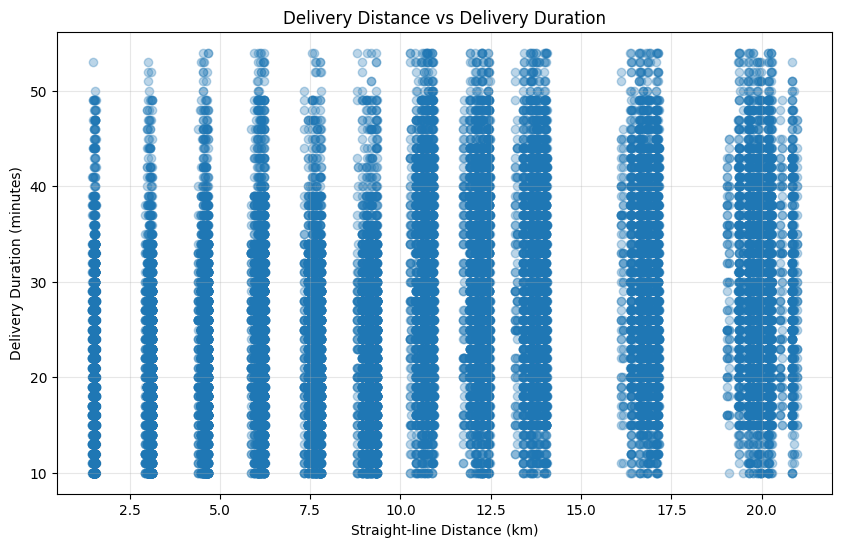

In [13]:
# Calculate Pearson correlation
distance_duration_corr = distance_df[
    ["Distance_km", duration_col]
].corr(method="pearson").iloc[0, 1]

print(
    "Pearson correlation between distance and delivery duration:",
    round(distance_duration_corr, 3)
)

# Create an initial scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    distance_df["Distance_km"],
    distance_df[duration_col],
    alpha=0.3
)

plt.title("Delivery Distance vs Delivery Duration")
plt.xlabel("Straight-line Distance (km)")
plt.ylabel("Delivery Duration (minutes)")
plt.grid(alpha=0.3)

plt.show()

### Pearson Correlation Interpretation

The Pearson correlation coefficient between delivery distance
and delivery duration is **0.321**.

This indicates a positive, weak-to-moderate linear relationship
between the two variables.

Longer delivery distances tend to be associated with longer
delivery durations. However, the relationship is not strong,
suggesting that other operational factors may also be related
to delivery time.

The analysis is based on 41,513 records with usable
restaurant coordinates. Distance represents straight-line
distance, not actual road distance.

Correlation does not imply causation.

## 7. Additional Operational Factors

### Multiple Deliveries and Delivery Person Ratings

This section examines the recorded values and distribution
of multiple deliveries and delivery person ratings.

The analysis will use the available dataset fields without
assuming undocumented meanings.

In [14]:
# Inspect multiple deliveries values
print("Multiple Deliveries - Value Counts")
display(
    df["multiple_deliveries"]
    .value_counts(dropna=False)
    .sort_index()
)

# Inspect delivery person ratings values
print("Delivery Person Ratings - Value Counts")
display(
    df["Delivery_person_Ratings"]
    .value_counts(dropna=False)
    .sort_index()
)

Multiple Deliveries - Value Counts


multiple_deliveries
0.00    14094
1.00    29144
2.00     1985
3.00      361
Name: count, dtype: int64

Delivery Person Ratings - Value Counts


Delivery_person_Ratings
1.00      38
2.50      20
2.60      22
2.70      22
2.80      19
2.90      19
3.00       6
3.10      29
3.20      29
3.30      25
3.40      32
3.50     249
3.60     207
3.70     225
3.80     228
3.90     197
4.00    1077
4.10    1430
4.20    1418
4.30    1409
4.40    1360
4.50    3302
4.60    6938
4.70    9048
4.80    7146
4.90    7040
5.00    3996
6.00      53
Name: count, dtype: int64

## 8. Multiple Deliveries and Delivery Person Ratings

This section compares delivery duration across the recorded
multiple delivery values and delivery person ratings.

The analysis uses group-level delivery counts, mean duration,
and median duration to identify differences between groups.

All recorded values are retained during this comparison.

In [15]:
# Compare delivery duration by multiple deliveries
multiple_deliveries_analysis = (
    df.groupby("multiple_deliveries", dropna=False)[duration_col]
    .agg(
        Delivery_Count="count",
        Mean_Duration="mean",
        Median_Duration="median"
    )
    .reset_index()
    .sort_values("multiple_deliveries")
)

print("Delivery Duration by Multiple Deliveries")
display(multiple_deliveries_analysis)


# Compare delivery duration by delivery person ratings
ratings_analysis = (
    df.groupby("Delivery_person_Ratings", dropna=False)[duration_col]
    .agg(
        Delivery_Count="count",
        Mean_Duration="mean",
        Median_Duration="median"
    )
    .reset_index()
    .sort_values("Delivery_person_Ratings")
)

print("Delivery Duration by Delivery Person Ratings")
display(ratings_analysis)


# Calculate Pearson correlation for ratings and duration
ratings_duration_corr = df[
    ["Delivery_person_Ratings", duration_col]
].corr(method="pearson").iloc[0, 1]

print(
    "Pearson correlation between ratings and delivery duration:",
    round(ratings_duration_corr, 3)
)

Delivery Duration by Multiple Deliveries


,multiple_deliveries,Delivery_Count,Mean_Duration,Median_Duration
0,0.00,14094,22.88,22.00
1,1.00,29144,26.72,26.00
2,2.00,1985,40.45,40.00
3,3.00,361,47.82,48.00


Delivery Duration by Delivery Person Ratings


,Delivery_person_Ratings,Delivery_Count,Mean_Duration,Median_Duration
0,1.00,38,26.00,26.50
1,2.50,20,37.30,35.50
2,2.60,22,38.59,39.00
3,2.70,22,35.86,36.50
4,2.80,19,36.63,37.00
5,2.90,19,38.53,39.00
6,3.00,6,32.67,32.50
7,3.10,29,36.55,35.00
8,3.20,29,36.34,36.00
9,3.30,25,36.04,36.00


Pearson correlation between ratings and delivery duration: -0.331


### Multiple Deliveries - Findings

Delivery duration increases across the recorded
multiple_deliveries values.

The mean duration ranges from 22.88 minutes for value 0
to 47.82 minutes for value 3.

The difference between these two groups is 24.94 minutes.

The group with value 3 contains 361 records, compared
with 14,094 records in group 0. Therefore, the smaller
group should be interpreted with caution.

These results show an association between the recorded
multiple_deliveries values and delivery duration.
They do not establish causation.


### Delivery Person Ratings - Findings

The Pearson correlation between delivery person ratings
and delivery duration is -0.331, indicating a negative,
weak-to-moderate linear association.

However, 1,908 originally missing rating values were
imputed using the median rating of 4.7 during Week 1.
Therefore, the correlation includes imputed values.

The dataset also contains a rating value of 6, whose
validity cannot be confirmed from the available information.

Consequently, this result should be treated as exploratory
and interpreted with caution.

Correlation does not imply causation.

## 9. Evidence-Based Observations

This section summarizes key findings from the exploratory
data analysis.

Each observation includes an analytical question, the
metric used, the observed result, group sizes, and a
careful interpretation.

The findings describe associations and patterns in the
dataset. They do not establish causal relationships.


### Observation 1: Traffic Density and Delivery Duration

**Analytical Question:**
How does delivery duration differ across traffic density levels?

**Metric:** Mean delivery duration.

**Observed Results:**
- Jam: 31.18 minutes (14,139 records).
- Low: 21.46 minutes (16,077 records).
- Difference: 9.72 minutes.

**Interpretation:**
Records classified under Jam traffic have a higher average
delivery duration than records classified under Low traffic.

This suggests an association between traffic density and
delivery duration.

The traffic variable includes values imputed during Week 1.


### Observation 2: Weather Conditions and Delivery Duration

**Analytical Question:**
How does delivery duration vary across weather conditions?

**Metric:** Mean delivery duration.

**Observed Results:**
- Cloudy: 28.92 minutes (7,533 records).
- Sunny: 21.86 minutes (7,282 records).
- Difference: 7.06 minutes.

**Interpretation:**
The average delivery duration is higher under Cloudy
conditions than under Sunny conditions.

This indicates an association between recorded weather
conditions and delivery duration.

The weather variable includes values imputed during Week 1.


### Observation 3: Vehicle Type and Delivery Duration

**Analytical Question:**
Do average delivery durations differ by vehicle type?

**Metric:** Mean delivery duration.

**Observed Results:**
- Motorcycle: 27.61 minutes (26,429 records).
- Scooter: 24.48 minutes (15,273 records).
- Difference: 3.13 minutes.

**Interpretation:**
Motorcycle records have a higher average delivery duration
than scooter records in this dataset.

This is a descriptive comparison and does not demonstrate
that vehicle type causes the difference.


### Observation 4: Multiple Deliveries and Delivery Duration

**Analytical Question:**
How does delivery duration vary across recorded
multiple_deliveries values?

**Metric:** Mean delivery duration.

**Observed Results:**
- Value 0: 22.88 minutes (14,094 records).
- Value 1: 26.72 minutes (29,144 records).
- Value 2: 40.45 minutes (1,985 records).
- Value 3: 47.82 minutes (361 records).

The difference between values 0 and 3 is 24.94 minutes.

**Interpretation:**
Average delivery duration increases across the recorded
multiple_deliveries values.

The group with value 3 has a relatively small sample size
compared with the other groups, so its result should be
interpreted cautiously.

The observed pattern does not establish causation.


### Observation 5: Delivery Distance and Delivery Duration

**Analytical Question:**
Is delivery distance linearly associated with delivery duration?

**Metric:** Pearson correlation coefficient.

**Observed Results:**
- Pearson correlation: 0.321.
- Records included: 41,513.

**Interpretation:**
The correlation indicates a positive, weak-to-moderate
linear association between straight-line delivery distance
and delivery duration.

Longer distances tend to be associated with longer
delivery durations, although the relationship is not strong.

Distance was calculated using valid coordinate records
and represents straight-line distance rather than road distance.

Correlation does not imply causation.

## 10. Limitations and Data Considerations

The following limitations should be considered when
interpreting the exploratory analysis results.

### 1. Missing Values and Imputation

Several columns contained missing values during Week 1.

- Delivery person ratings: 1,908 missing values were
  imputed using the median (4.7).
- Delivery person age: 1,854 missing values were
  imputed using the median (30).
- Multiple deliveries: 993 missing values were
  imputed using the mode (1).
- Weather conditions: 616 missing values were
  imputed using the mode (Fog).
- Road traffic density: 601 missing values were
  imputed using the mode (Low).
- Time_Orderd: 1,731 missing values were retained
  without imputation.

Group comparisons involving imputed variables may be
influenced by the imputation process.


### 2. Delivery Distance Limitations

Distance was calculated using the Haversine formula
based on geographical coordinates.

The calculated distance represents straight-line
distance, not actual road distance.

A total of 4,071 records were excluded from the
distance analysis because their restaurant coordinates
contained zero or negative values.

These records were excluded only from distance calculations
and were not removed from the main dataset.

The suspicious coordinate values were not corrected
because their actual locations could not be confirmed.


### 3. Outliers

Statistical outliers were identified in some numerical
columns during Week 1.

However, these records were retained in the dataset
because an outlier does not necessarily represent an
incorrect observation.

Extreme values may influence summary statistics
and group comparisons.


### 4. Delivery Partner Experience

The dataset does not contain a direct field measuring
delivery partner experience or years of service.

Therefore, delivery partner experience could not be
evaluated.

Delivery person age was not used as a substitute
for experience.


### 5. Rating Values

The ratings column contains a recorded value of 6.

The valid rating scale could not be confirmed from
the available dataset documentation.

Additionally, missing rating values were imputed
using the median during Week 1.

Therefore, rating-related findings should be
interpreted cautiously.


### 6. Correlation and Causation

The correlations and group comparisons in this notebook
describe statistical associations.

They do not prove that one variable causes changes
in delivery duration.

Other operational factors may influence the observed
relationships.


### 7. Group Size Differences

Some categories contain considerably fewer records
than others.

For example, the vehicle category Bicycle contains
only 68 records, while the Motorcycle category contains
26,429 records.

Comparisons involving small groups should be interpreted
with caution.